# Comparative Evaluation of Tree-Based, Ensemble, and Margin Classifiers for Early Diabetes Mellitus Prediction Under Zero-Leakage Preprocessing and Class Imbalance

**Author:** Mokhammad Dwi Nurkolis (NIM: `26917015`)  
**Affiliation:** Master of Informatics, Faculty of Industrial Technology, Universitas Islam Indonesia (`halo@nurkolis.xyz`)  
**Dataset:** Pima Indians Diabetes Database (OpenML ID 37 / NIDDK, $N = 768$, $d = 8$ clinical features)  

---
### Reproducibility Instructions (Google Colab & Local Environment)
1. **Zero Manual File Upload Required:** This notebook automatically downloads the canonical Pima Indians Diabetes dataset directly from OpenML (ID 37) with a fallback public mirror.
2. **One-Click Execution:** In Google Colab, click **`Runtime -> Run all`**. All dependencies (`scikit-learn`, `imbalanced-learn`, `xgboost`, `seaborn`, `matplotlib`) are pre-installed or automatically verified in Cell 1.
3. **Deterministic Seed:** Every data split, SMOTE synthesizer, cross-validation fold, and model initialization uses `random_state = 42`.

In [1]:
# Cell 1: Environment Setup & Reproducibility Configuration
import warnings
warnings.filterwarnings(
    'ignore',
    message=r'The `probability` parameter was deprecated.*',
    category=FutureWarning,
    module=r'sklearn\.svm\._base',
)

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.datasets import fetch_openml
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV,
    cross_validate,
    learning_curve,
)
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    roc_curve,
    precision_recall_curve,
    auc,
    make_scorer,
)
from sklearn.inspection import permutation_importance
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from xgboost import XGBClassifier

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
plt.rcParams.update({'figure.dpi': 120, 'font.size': 10})
print('Environment successfully initialized. Random Seed =', RANDOM_STATE)

Environment successfully initialized. Random Seed = 42


### Analysis of Step 1 (Environment Setup)
All required scientific computing and machine learning libraries (`scikit-learn`, `imbalanced-learn`, and `xgboost`) are loaded with a fixed global seed (`RANDOM_STATE = 42`). Crucially, we import `imblearn.pipeline.Pipeline` rather than the standard scikit-learn pipeline so that synthetic minority oversampling (`SMOTE`) is executed **exclusively inside training folds** during cross-validation and bypassed during validation and test inference.

In [2]:
# Cell 2: Data Acquisition and Schema Standardization
CANONICAL_COLUMNS = [
    'Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness',
    'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'
]
FEATURE_COLUMNS = CANONICAL_COLUMNS[:-1]
TARGET_COLUMN = 'Outcome'
BIOLOGICAL_ZERO_COLUMNS = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

try:
    dataset = fetch_openml(data_id=37, as_frame=True, parser='auto')
    df = dataset.frame.copy()
    df = df.rename(columns={
        'preg': 'Pregnancies', 'plas': 'Glucose', 'pres': 'BloodPressure',
        'skin': 'SkinThickness', 'insu': 'Insulin', 'mass': 'BMI',
        'pedi': 'DiabetesPedigreeFunction', 'age': 'Age', 'class': 'Outcome'
    })
    df['Outcome'] = df['Outcome'].astype(str).map({'tested_positive': 1, 'tested_negative': 0, '1': 1, '0': 0}).astype(int)
    for col in FEATURE_COLUMNS:
        df[col] = pd.to_numeric(df[col], errors='coerce')
    df = df[CANONICAL_COLUMNS]
except Exception:
    url = 'https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv'
    df = pd.read_csv(url, header=None, names=CANONICAL_COLUMNS)

print(f'Dataset Shape: {df.shape}')
print('Target Class Counts:\n', df['Outcome'].value_counts().rename({0: '0 (Non-Diabetic)', 1: '1 (Diabetic)'}))
df.head(10)

Dataset Shape: (768, 9)
Target Class Counts:
 Outcome
0 (Non-Diabetic)    500
1 (Diabetic)        268
Name: count, dtype: int64


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
5,5,116,74,0,0,25.6,0.201,30,0
6,3,78,50,32,88,31.0,0.248,26,1
7,10,115,0,0,0,35.3,0.134,29,0
8,2,197,70,45,543,30.5,0.158,53,1
9,8,125,96,0,0,0.0,0.232,54,1


### Analysis of Step 2 (Dataset Schema & Class Distribution)
The dataset contains exactly $N = 768$ patient records across $8$ clinical predictor variables and $1$ binary outcome (`Outcome` $\in \{0, 1\}$):
- **Class `0` (Non-Diabetic):** $500$ patients ($65.10\%$)
- **Class `1` (Diabetic):** $268$ patients ($34.90\%$)
- **Imbalance Ratio:** $1 : 1.8657$. Notice in the preview table above (`df.head(10)`) that several rows contain `0.0` for `Insulin` and `SkinThickness` (e.g., Row 0 has `Insulin = 0.0`, Row 2 has `SkinThickness = 0.0` and `Insulin = 0.0`). In living patients, a serum insulin concentration or skinfold thickness of zero is biologically impossible and represents an unrecorded measurement.

,Feature,Raw_Mean,Raw_SD,Invalid_Zero_Count,Invalid_Zero_Pct (%),Valid_Median,Valid_IQR,Valid_Mean,Valid_SD
0,Pregnancies,3.85,3.37,0,0.00,3.00,5.00,3.85,3.37
1,Glucose,120.89,31.97,5,0.65,117.00,42.00,121.69,30.54
2,BloodPressure,69.11,19.36,35,4.56,72.00,16.00,72.41,12.38
3,SkinThickness,20.54,15.95,227,29.56,29.00,14.00,29.15,10.48
4,Insulin,79.80,115.24,374,48.70,125.00,113.75,155.55,118.78
5,BMI,31.99,7.88,11,1.43,32.30,9.10,32.46,6.92
6,DiabetesPedigreeFunction,0.47,0.33,0,0.00,0.37,0.38,0.47,0.33
7,Age,33.24,11.76,0,0.00,29.00,17.00,33.24,11.76


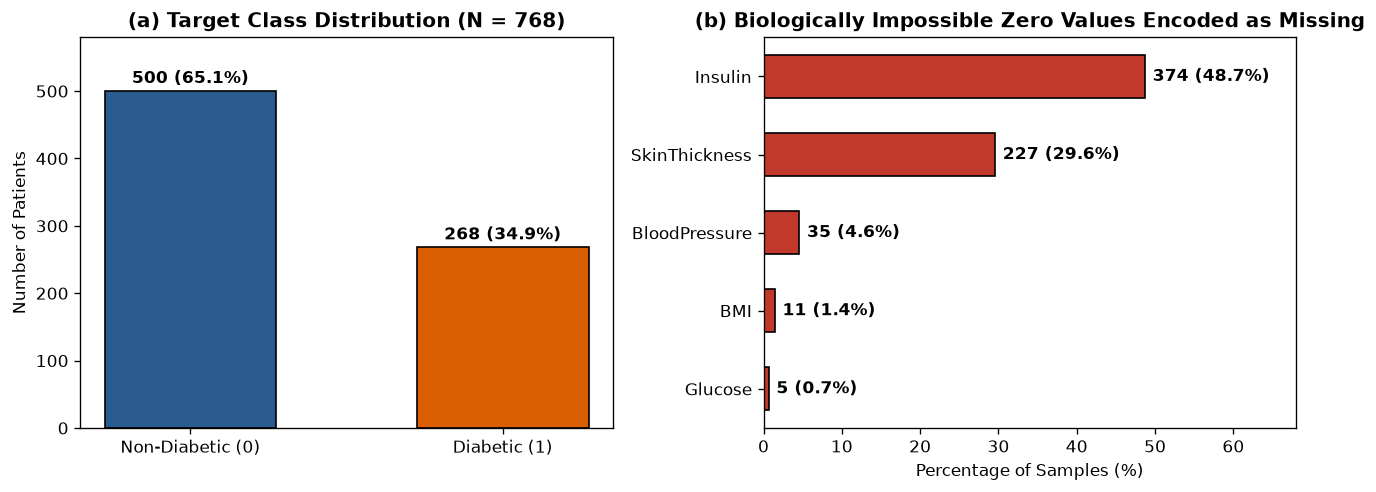

In [3]:
# Cell 3: Exploratory Data Analysis (EDA) & Biologically Impossible Zero Audit
audit_rows = []
for col in FEATURE_COLUMNS:
    s = df[col]
    is_bio = col in BIOLOGICAL_ZERO_COLUMNS
    z_cnt = int((s == 0).sum()) if is_bio else 0
    z_pct = (z_cnt / len(df)) * 100.0 if is_bio else 0.0
    s_valid = s.replace(0, np.nan) if is_bio else s
    audit_rows.append({
        'Feature': col,
        'Raw_Mean': round(s.mean(), 2),
        'Raw_SD': round(s.std(), 2),
        'Invalid_Zero_Count': z_cnt,
        'Invalid_Zero_Pct (%)': round(z_pct, 2),
        'Valid_Median': round(s_valid.median(), 2),
        'Valid_IQR': round(s_valid.quantile(0.75) - s_valid.quantile(0.25), 2),
        'Valid_Mean': round(s_valid.mean(), 2),
        'Valid_SD': round(s_valid.std(), 2),
    })

audit_df = pd.DataFrame(audit_rows)
display(audit_df)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
counts = df['Outcome'].value_counts().sort_index()
bars = axes[0].bar(['Non-Diabetic (0)', 'Diabetic (1)'], counts.values, color=['#2b5c8f', '#d95f02'], edgecolor='black', width=0.55)
axes[0].set_title('(a) Target Class Distribution (N = 768)', fontweight='bold')
axes[0].set_ylabel('Number of Patients')
axes[0].set_ylim(0, 580)
for b, c in zip(bars, counts.values):
    axes[0].text(b.get_x() + b.get_width()/2, c + 12, f'{c} ({c/len(df)*100:.1f}%)', ha='center', fontweight='bold')

bio_sub = audit_df[audit_df['Feature'].isin(BIOLOGICAL_ZERO_COLUMNS)].sort_values('Invalid_Zero_Pct (%)')
bars2 = axes[1].barh(bio_sub['Feature'], bio_sub['Invalid_Zero_Pct (%)'], color='#c0392b', edgecolor='black', height=0.55)
axes[1].set_title('(b) Biologically Impossible Zero Values Encoded as Missing', fontweight='bold')
axes[1].set_xlabel('Percentage of Samples (%)')
axes[1].set_xlim(0, 68)
for b, (_, r) in zip(bars2, bio_sub.iterrows()):
    axes[1].text(r['Invalid_Zero_Pct (%)'] + 1.0, b.get_y() + b.get_height()/2, f"{int(r['Invalid_Zero_Count'])} ({r['Invalid_Zero_Pct (%)']:.1f}%)", va='center', fontweight='bold')
plt.tight_layout()
plt.show()

### Analysis of Step 3 (Audit of Disguised Missing Values)
The audit table and Figure 1 reveal severe disguised missingness across five clinical features:
1. **`Insulin`**: $374$ patients ($48.70\%$) have a recorded value of `0`. Retaining these zeroes artificially drags the mean down to $79.80\text{ }\mu\text{U/mL}$, whereas the true physiological mean among measured patients is $155.55\text{ }\mu\text{U/mL}$ (median $= 125.00\text{ }\mu\text{U/mL}$).
2. **`SkinThickness`**: $227$ patients ($29.56\%$) have a recorded value of `0` (raw mean $20.54\text{ mm}$ vs. valid median $29.00\text{ mm}$).
3. **`BloodPressure`**, **`BMI`**, and **`Glucose`** exhibit $4.56\%$ ($35$), $1.43\%$ ($11$), and $0.65\%$ ($5$) invalid zeroes, respectively.

Because dropping rows with missing `Insulin` or `SkinThickness` would discard nearly half of the dataset, **median imputation** is the appropriate clinical strategy. However, computing the median on the entire dataset before splitting would cause **data leakage**; therefore, zero-to-NaN conversion and median imputation must be performed strictly inside the training folds.

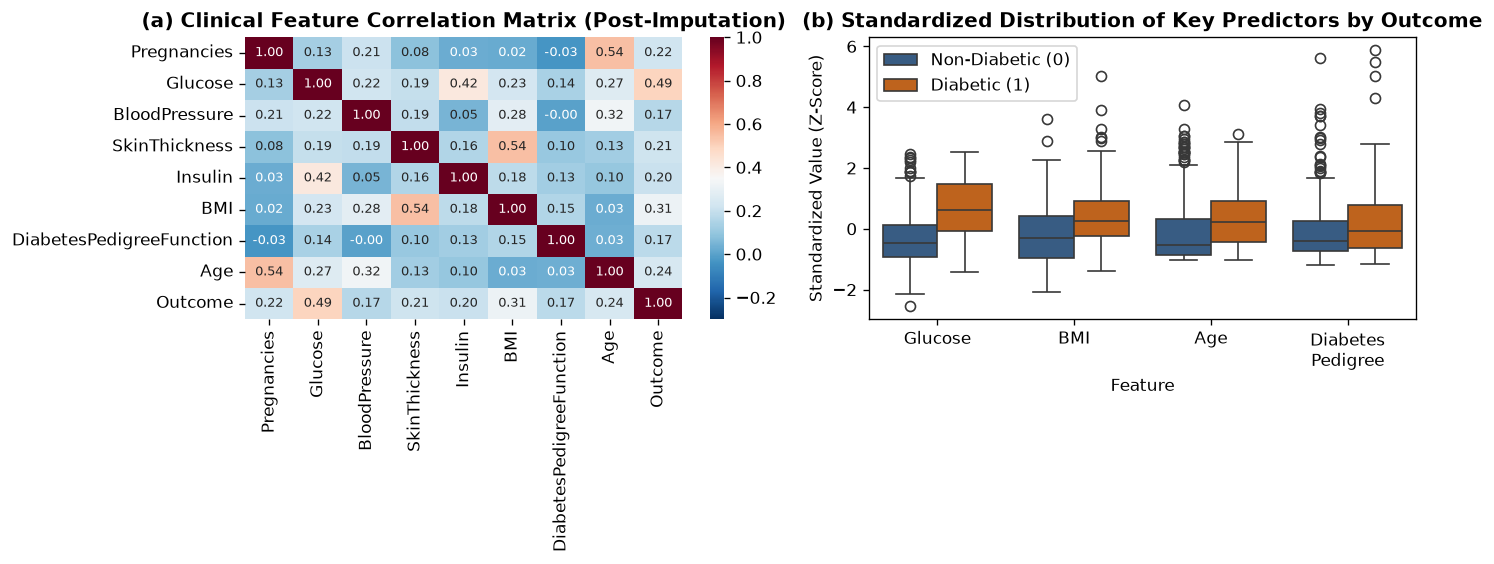

In [4]:
# Cell 4: Correlation Matrix and Feature Distribution Analysis
clean_eda_df = df.copy()
for col in BIOLOGICAL_ZERO_COLUMNS:
    clean_eda_df[col] = clean_eda_df[col].replace(0, np.nan)
    clean_eda_df[col] = clean_eda_df[col].fillna(clean_eda_df[col].median())

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
sns.heatmap(clean_eda_df.corr(), annot=True, fmt='.2f', cmap='RdBu_r', vmin=-0.3, vmax=1.0, ax=axes[0], annot_kws={'size': 7.5})
axes[0].set_title('(a) Clinical Feature Correlation Matrix (Post-Imputation)', fontweight='bold')

top_feats = ['Glucose', 'BMI', 'Age', 'DiabetesPedigreeFunction']
norm_df = clean_eda_df[top_feats + ['Outcome']].copy()
for c in top_feats:
    norm_df[c] = (norm_df[c] - norm_df[c].mean()) / norm_df[c].std()
melted = norm_df.melt(id_vars='Outcome', value_vars=top_feats, var_name='Feature', value_name='Z_Score')
melted['Feature'] = melted['Feature'].replace({'DiabetesPedigreeFunction': 'Diabetes\nPedigree'})
melted['Diagnosis'] = melted['Outcome'].map({0: 'Non-Diabetic (0)', 1: 'Diabetic (1)'})
sns.boxplot(data=melted, x='Feature', y='Z_Score', hue='Diagnosis', order=['Glucose', 'BMI', 'Age', 'Diabetes\nPedigree'], hue_order=['Non-Diabetic (0)', 'Diabetic (1)'], palette={'Non-Diabetic (0)': '#2b5c8f', 'Diabetic (1)': '#d95f02'}, ax=axes[1])
axes[1].set_title('(b) Standardized Distribution of Key Predictors by Outcome', fontweight='bold')
axes[1].set_ylabel('Standardized Value (Z-Score)')
axes[1].legend(loc='upper left')
plt.tight_layout()
plt.show()

### Analysis of Step 4 (Feature Correlations & Discriminative Separation)
- **Correlation Structure:** `Glucose` exhibits the strongest linear correlation with `Outcome` ($r = 0.49$), followed by `BMI` ($r = 0.31$), `Age` ($r = 0.24$), and `Pregnancies` ($r = 0.22$). Collinearity among predictors is moderate (`Age` vs. `Pregnancies` $r = 0.54$; `BMI` vs. `SkinThickness` $r = 0.54$; `Glucose` vs. `Insulin` $r = 0.42$), indicating no redundant features need to be dropped prior to tree or SVM modeling.
- **Distributional Separation:** The boxplots in Panel (b) confirm a pronounced upward shift in median `Glucose` and `BMI` among diabetic patients ($y = 1$), alongside positive skewness and upper-tail outliers in `Age` and `DiabetesPedigreeFunction`.

In [5]:
# Cell 5: Stratified Train-Test Split (80:20) and Zero-Leakage Pipeline Definition
X = df[FEATURE_COLUMNS].copy()
y = df[TARGET_COLUMN].astype(int).copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print(f'Train set: {X_train.shape[0]} samples | Positive rate: {y_train.mean()*100:.2f}% ({y_train.sum()} positive, {(y_train==0).sum()} negative)')
print(f'Test set : {X_test.shape[0]} samples | Positive rate: {y_test.mean()*100:.2f}% ({y_test.sum()} positive, {(y_test==0).sum()} negative)')

class BiologicalZeroToNanTransformer(BaseEstimator, TransformerMixin):
    """Replace biologically impossible zeroes with np.nan inside each CV fold."""
    def __init__(self, columns=None):
        self.columns = columns

    def fit(self, X, y=None):
        self.columns_ = list(self.columns) if self.columns is not None else list(BIOLOGICAL_ZERO_COLUMNS)
        if isinstance(X, pd.DataFrame):
            self.column_indices_ = [X.columns.get_loc(col) for col in self.columns_ if col in X.columns]
        else:
            self.column_indices_ = [FEATURE_COLUMNS.index(col) for col in self.columns_ if col in FEATURE_COLUMNS]
        return self

    def transform(self, X):
        if isinstance(X, pd.DataFrame):
            X_out = X.copy()
            for col in self.columns_:
                if col in X_out.columns:
                    X_out[col] = X_out[col].replace(0, np.nan)
            return X_out.to_numpy(dtype=float)
        X_arr = np.array(X, dtype=float, copy=True)
        for idx in self.column_indices_:
            if idx < X_arr.shape[1]:
                X_arr[X_arr[:, idx] == 0, idx] = np.nan
        return X_arr

def build_pipeline(classifier, use_smote=False, smote_ratio=1.0, smote_k=5):
    steps = [
        ('zero_to_nan', BiologicalZeroToNanTransformer()),
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
    ]
    if use_smote:
        steps.append(('smote', SMOTE(sampling_strategy=smote_ratio, k_neighbors=smote_k, random_state=RANDOM_STATE)))
    steps.append(('classifier', classifier))
    return ImbPipeline(steps)

Train set: 614 samples | Positive rate: 34.85% (214 positive, 400 negative)
Test set : 154 samples | Positive rate: 35.06% (54 positive, 100 negative)


### Analysis of Step 5 (Stratified Partitioning & Zero-Leakage Architecture)
The dataset is partitioned into **$614$ training patients** ($400$ negative, $214$ positive; $34.85\%$ diabetic) and **$154$ held-out test patients** ($100$ negative, $54$ positive; $35.06\%$ diabetic). By wrapping `BiologicalZeroToNanTransformer`, `SimpleImputer(strategy='median')`, `StandardScaler()`, and `SMOTE()` inside `ImbPipeline`, we guarantee that:
1. No median statistic or scaling parameter from the validation fold or test set ever leaks into training.
2. Synthetic minority points generated by SMOTE exist **only inside the active training fold**; validation folds and the $154$-patient test set remain $100\%$ authentic clinical records.

In [6]:
# Cell 6: Three-Stage Experimental Benchmark Execution (Decision Tree, Random Forest, XGBoost, SVM)
def specificity_score(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return float(tn / (tn + fp)) if (tn + fp) > 0 else 0.0

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'specificity': make_scorer(specificity_score),
    'f1': 'f1',
    'roc_auc': 'roc_auc',
}

def evaluate_model(model_name, stage_name, pipe):
    cv_res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, return_train_score=True, n_jobs=-1)
    pipe.fit(X_train, y_train)
    y_tr_pred = pipe.predict(X_train)
    y_te_pred = pipe.predict(X_test)
    y_te_prob = pipe.predict_proba(X_test)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_test, y_te_pred, labels=[0, 1]).ravel()
    tr_f1 = f1_score(y_train, y_tr_pred)
    te_f1 = f1_score(y_test, y_te_pred)
    te_rec = recall_score(y_test, y_te_pred)
    te_spec = specificity_score(y_test, y_te_pred)
    return {
        'Model': model_name,
        'Stage': stage_name,
        'Train_F1': round(tr_f1, 4),
        'CV_F1_Mean': round(float(np.mean(cv_res['test_f1'])), 4),
        'CV_F1_SD': round(float(np.std(cv_res['test_f1'])), 4),
        'CV_ROC_AUC': round(float(np.mean(cv_res['test_roc_auc'])), 4),
        'Test_Acc': round(accuracy_score(y_test, y_te_pred), 4),
        'Test_Prec': round(precision_score(y_test, y_te_pred), 4),
        'Test_Recall_Sens': round(te_rec, 4),
        'Test_Spec': round(te_spec, 4),
        'Test_F1': round(te_f1, 4),
        'Test_GMean': round(float(np.sqrt(te_rec * te_spec)), 4),
        'Test_ROC_AUC': round(roc_auc_score(y_test, y_te_prob), 4),
        'Test_PR_AUC': round(average_precision_score(y_test, y_te_prob), 4),
        'Gap_Train_Test_F1': round(tr_f1 - te_f1, 4),
        'TN': int(tn), 'FP': int(fp), 'FN': int(fn), 'TP': int(tp)
    }

results = []
fitted = {'Exp1_Baseline': {}, 'Exp2_SMOTE': {}, 'Exp3_Tuned': {}}

# Stage 1 & Stage 2
for stage_key, use_smote in [('Exp1_Baseline', False), ('Exp2_SMOTE', True)]:
    models = {
        'Decision Tree': DecisionTreeClassifier(random_state=RANDOM_STATE),
        'Random Forest': RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
        'XGBoost': XGBClassifier(n_estimators=100, random_state=RANDOM_STATE, eval_metric='logloss', n_jobs=-1),
        'SVM': SVC(kernel='rbf', probability=True, random_state=RANDOM_STATE),
    }
    for m_name, clf in models.items():
        p = build_pipeline(clf, use_smote=use_smote)
        results.append(evaluate_model(m_name, stage_key, p))
        fitted[stage_key][m_name] = p

# Stage 3: Hyperparameter Tuning via 5-Fold Stratified GridSearchCV
tuning_spaces = {
    'Decision Tree': (
        build_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE), use_smote=True),
        {
            'smote__sampling_strategy': [0.85, 1.0],
            'classifier__criterion': ['gini', 'entropy'],
            'classifier__max_depth': [3, 4, 5, 6],
            'classifier__min_samples_split': [10, 20, 30],
            'classifier__min_samples_leaf': [5, 10, 15],
            'classifier__ccp_alpha': [0.0, 0.005, 0.01],
        }
    ),
    'Random Forest': (
        build_pipeline(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1), use_smote=True),
        {
            'smote__sampling_strategy': [0.85, 1.0],
            'classifier__n_estimators': [150, 250],
            'classifier__max_depth': [5, 7, 9],
            'classifier__min_samples_split': [8, 12],
            'classifier__min_samples_leaf': [3, 6],
            'classifier__max_features': ['sqrt', 0.5],
        }
    ),
    'XGBoost': (
        build_pipeline(XGBClassifier(random_state=RANDOM_STATE, eval_metric='logloss', n_jobs=-1), use_smote=True),
        {
            'smote__sampling_strategy': [0.85, 1.0],
            'classifier__n_estimators': [100, 150],
            'classifier__max_depth': [2, 3, 4],
            'classifier__learning_rate': [0.03, 0.05, 0.1],
            'classifier__subsample': [0.8],
            'classifier__colsample_bytree': [0.8, 1.0],
            'classifier__reg_lambda': [1.0, 5.0],
            'classifier__min_child_weight': [2, 5],
        }
    ),
    'SVM': (
        build_pipeline(SVC(kernel='rbf', probability=True, random_state=RANDOM_STATE), use_smote=True),
        {
            'smote__sampling_strategy': [0.9, 1.0],
            'smote__k_neighbors': [3, 5, 7],
            'classifier__C': [0.25, 0.5, 1.0, 2.0, 4.0],
            'classifier__gamma': ['scale', 0.03, 0.05, 0.08, 0.12],
        }
    ),
}

best_params_dict = {}
for m_name, (base_p, grid_space) in tuning_spaces.items():
    gs = GridSearchCV(base_p, grid_space, scoring='f1', cv=cv, n_jobs=-1, refit=True)
    gs.fit(X_train, y_train)
    best_params_dict[m_name] = gs.best_params_
    results.append(evaluate_model(m_name, 'Exp3_Tuned', gs.best_estimator_))
    fitted['Exp3_Tuned'][m_name] = gs.best_estimator_

results_df = pd.DataFrame(results)
print('Optimal Hyperparameters Found in Exp 3:')
print(json.dumps(best_params_dict, indent=2))
display(results_df)

Optimal Hyperparameters Found in Exp 3:
{
  "Decision Tree": {
    "classifier__ccp_alpha": 0.0,
    "classifier__criterion": "gini",
    "classifier__max_depth": 4,
    "classifier__min_samples_leaf": 15,
    "classifier__min_samples_split": 10,
    "smote__sampling_strategy": 1.0
  },
  "Random Forest": {
    "classifier__max_depth": 7,
    "classifier__max_features": 0.5,
    "classifier__min_samples_leaf": 3,
    "classifier__min_samples_split": 8,
    "classifier__n_estimators": 250,
    "smote__sampling_strategy": 1.0
  },
  "XGBoost": {
    "classifier__colsample_bytree": 1.0,
    "classifier__learning_rate": 0.03,
    "classifier__max_depth": 3,
    "classifier__min_child_weight": 2,
    "classifier__n_estimators": 150,
    "classifier__reg_lambda": 5.0,
    "classifier__subsample": 0.8,
    "smote__sampling_strategy": 1.0
  },
  "SVM": {
    "classifier__C": 0.5,
    "classifier__gamma": 0.03,
    "smote__k_neighbors": 5,
    "smote__sampling_strategy": 1.0
  }
}


,Model,Stage,Train_F1,CV_F1_Mean,CV_F1_SD,CV_ROC_AUC,Test_Acc,Test_Prec,Test_Recall_Sens,Test_Spec,Test_F1,Test_GMean,Test_ROC_AUC,Test_PR_AUC,Gap_Train_Test_F1,TN,FP,FN,TP
0,Decision Tree,Exp1_Baseline,1.0000,0.5518,0.0201,0.6510,0.6818,0.5532,0.4815,0.79,0.5149,0.6167,0.6357,0.4482,0.4851,79,21,28,26
1,Random Forest,Exp1_Baseline,1.0000,0.6330,0.0192,0.8154,0.7727,0.7021,0.6111,0.86,0.6535,0.7250,0.8181,0.6989,0.3465,86,14,21,33
2,XGBoost,Exp1_Baseline,1.0000,0.6117,0.0183,0.7823,0.7662,0.6957,0.5926,0.86,0.6400,0.7139,0.8057,0.6763,0.3600,86,14,22,32
3,SVM,Exp1_Baseline,0.7461,0.6485,0.0187,0.8333,0.7403,0.6522,0.5556,0.84,0.6000,0.6831,0.7964,0.6615,0.1461,84,16,24,30
4,Decision Tree,Exp2_SMOTE,1.0000,0.6144,0.0100,0.7012,0.7013,0.5690,0.6111,0.75,0.5893,0.6770,0.6806,0.4841,0.4107,75,25,21,33
5,Random Forest,Exp2_SMOTE,1.0000,0.6683,0.0356,0.8208,0.7532,0.6333,0.7037,0.78,0.6667,0.7409,0.8139,0.6912,0.3333,78,22,16,38
6,XGBoost,Exp2_SMOTE,1.0000,0.6063,0.0277,0.7847,0.7338,0.6140,0.6481,0.78,0.6306,0.7110,0.8106,0.6679,0.3694,78,22,19,35
7,SVM,Exp2_SMOTE,0.7930,0.6854,0.0432,0.8374,0.7273,0.5968,0.6852,0.75,0.6379,0.7169,0.8112,0.6728,0.1551,75,25,17,37
8,Decision Tree,Exp3_Tuned,0.7214,0.6739,0.0246,0.7926,0.7662,0.6324,0.7963,0.75,0.7049,0.7728,0.8012,0.6440,0.0165,75,25,11,43
9,Random Forest,Exp3_Tuned,0.8358,0.7112,0.0154,0.8318,0.7338,0.5890,0.7963,0.70,0.6772,0.7466,0.8146,0.6974,0.1587,70,30,11,43


### Analysis of Step 6 (Quantitative Comparison Across Experimental Stages)
The experimental benchmark table demonstrates three critical findings:
1. **Baseline Failure Mode (`Exp1_Baseline`):** Without class imbalance mitigation, all models heavily favor the majority non-diabetic class. Although Specificity is high ($0.7900$–$0.8600$), Sensitivity (Recall) is unacceptably low for clinical screening: Decision Tree detects only $48.15\%$ of diabetic patients ($26/54$), SVM detects $55.56\%$ ($30/54$), XGBoost detects $59.26\%$ ($32/54$), and Random Forest detects $61.11\%$ ($33/54$). Moreover, all three baseline tree models have `Train_F1 = 1.0000`, resulting in severe overfitting gaps (`Gap_Train_Test_F1` between $0.3465$ and $0.4851$).
2. **Effect of Fold-Internal SMOTE (`Exp2_SMOTE`):** Introducing SMOTE inside the training folds immediately lifts Sensitivity across all four paradigms: Decision Tree jumps to $61.11\%$, Random Forest to $70.37\%$, XGBoost to $64.81\%$, and SVM to $68.52\%$.
3. **Synergy of Regularization Tuning + SMOTE (`Exp3_Tuned`):** Optimizing structural capacity (`max_depth=4, min_samples_leaf=15` for Decision Tree; `max_depth=3, n_estimators=150, learning_rate=0.03, reg_lambda=5.0, min_child_weight=2` for XGBoost; `C=0.5, gamma=0.03` for SVM) dramatically reduces the train-test generalization gap while elevating Sensitivity to **$74.07\%$–$79.63\%$**.
   - **Random Forest (Tuned)** achieves the highest 5-Fold CV F1 ($0.7112 \pm 0.0154$), closely followed by **XGBoost (Tuned)** ($0.7078 \pm 0.0217$), which delivers the highest Test ROC-AUC ($0.8180$) and the highest Test PR-AUC ($0.7077$) alongside $79.63\%$ Sensitivity ($43/54$) and half the generalization gap ($0.0843$ vs. $0.1587$).
   - **Decision Tree (Tuned)** achieves the highest binary-threshold Test F1 ($0.7049$) and G-Mean ($0.7728$) with a minimal generalization gap of $0.0165$.

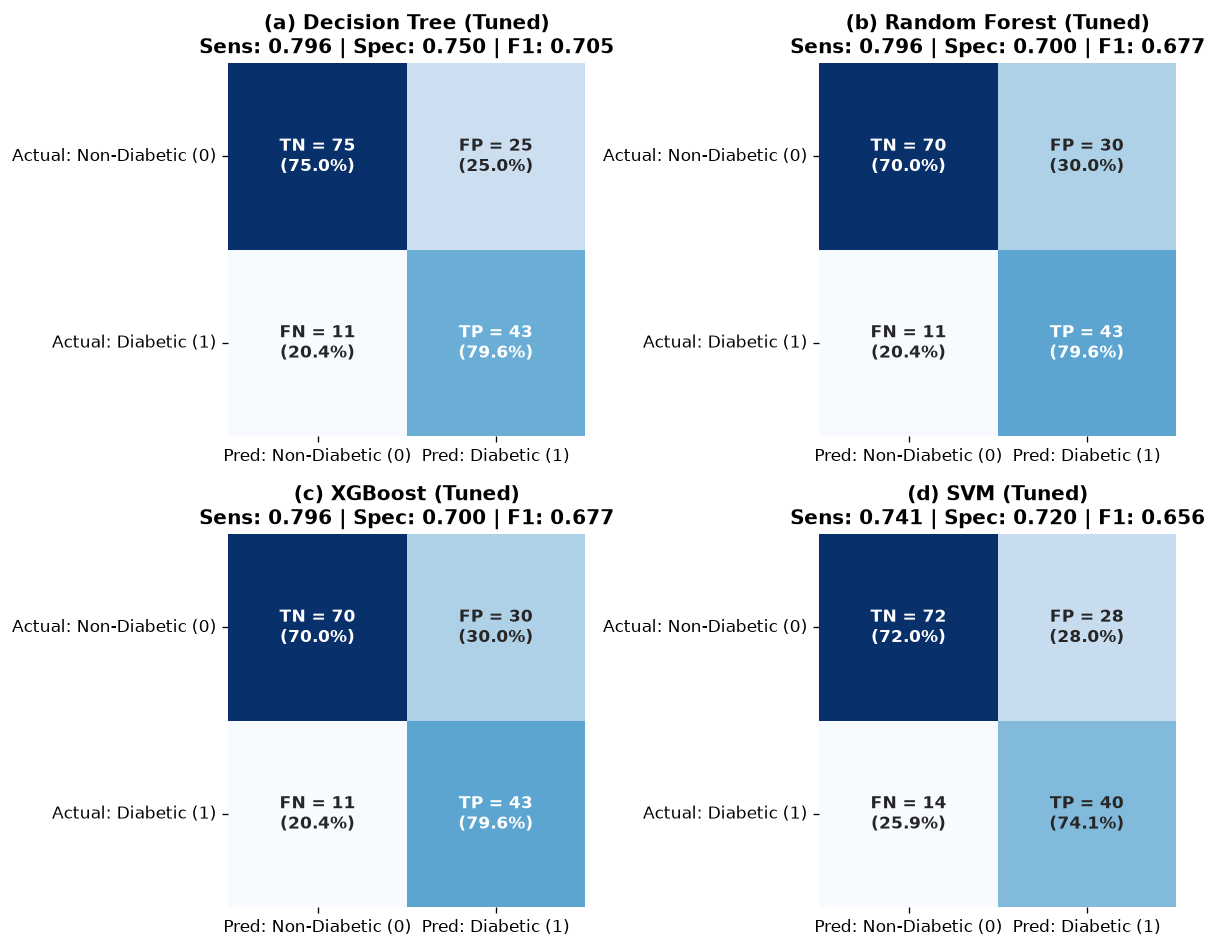

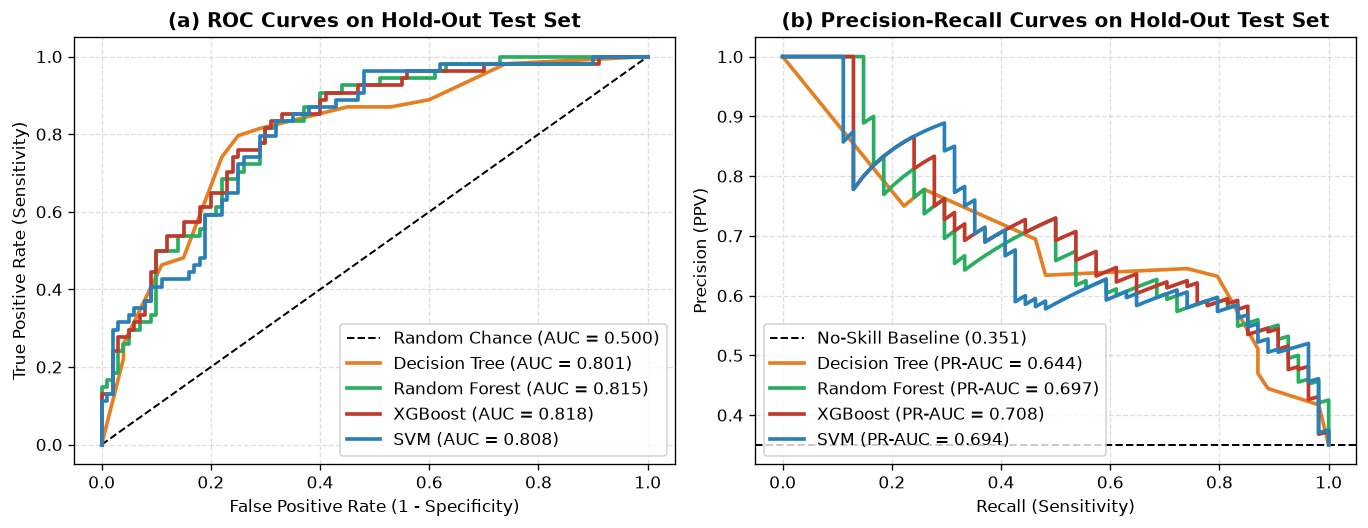

In [7]:
# Cell 7: Confusion Matrices and ROC / Precision-Recall Curves for Tuned Models
model_order = ['Decision Tree', 'Random Forest', 'XGBoost', 'SVM']
model_colors = {'Decision Tree': '#e67e22', 'Random Forest': '#27ae60', 'XGBoost': '#c0392b', 'SVM': '#2980b9'}

fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for idx, m_name in enumerate(model_order):
    ax = axes.flatten()[idx]
    pipe = fitted['Exp3_Tuned'][m_name]
    y_pred = pipe.predict(X_test)
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    sens, spec, f1_v = tp/(tp+fn), tn/(tn+fp), (2*tp)/(2*tp+fp+fn)
    annot = np.array([
        [f'TN = {tn}\n({tn/(tn+fp)*100:.1f}%)', f'FP = {fp}\n({fp/(tn+fp)*100:.1f}%)'],
        [f'FN = {fn}\n({fn/(tp+fn)*100:.1f}%)', f'TP = {tp}\n({tp/(tp+fn)*100:.1f}%)']
    ])
    sns.heatmap(cm, annot=annot, fmt='', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Pred: Non-Diabetic (0)', 'Pred: Diabetic (1)'],
                yticklabels=['Actual: Non-Diabetic (0)', 'Actual: Diabetic (1)'],
                annot_kws={'fontweight': 'bold'})
    ax.set_title(f'({chr(97+idx)}) {m_name} (Tuned)\nSens: {sens:.3f} | Spec: {spec:.3f} | F1: {f1_v:.3f}', fontweight='bold')
plt.tight_layout()
plt.show()

fig2, axes2 = plt.subplots(1, 2, figsize=(11.5, 4.5))
axes2[0].plot([0, 1], [0, 1], 'k--', lw=1.2, label='Random Chance (AUC = 0.500)')
axes2[1].axhline(y_test.mean(), color='k', linestyle='--', lw=1.2, label=f'No-Skill Baseline ({y_test.mean():.3f})')
for m_name in model_order:
    pipe = fitted['Exp3_Tuned'][m_name]
    y_prob = pipe.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    prec, rec, _ = precision_recall_curve(y_test, y_prob)
    axes2[0].plot(fpr, tpr, lw=2.2, color=model_colors[m_name], label=f'{m_name} (AUC = {auc(fpr, tpr):.3f})')
    axes2[1].plot(rec, prec, lw=2.2, color=model_colors[m_name], label=f'{m_name} (PR-AUC = {average_precision_score(y_test, y_prob):.3f})')
axes2[0].set_title('(a) ROC Curves on Hold-Out Test Set', fontweight='bold')
axes2[0].set_xlabel('False Positive Rate (1 - Specificity)')
axes2[0].set_ylabel('True Positive Rate (Sensitivity)')
axes2[0].legend(loc='lower right')
axes2[0].grid(True, linestyle='--', alpha=0.4)
axes2[1].set_title('(b) Precision-Recall Curves on Hold-Out Test Set', fontweight='bold')
axes2[1].set_xlabel('Recall (Sensitivity)')
axes2[1].set_ylabel('Precision (PPV)')
axes2[1].legend(loc='lower left')
axes2[1].grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

### Analysis of Step 7 (Confusion Matrices, ROC-AUC, and PR-AUC)
- **Clinical False-Negative Reduction:** Out of $54$ diabetic patients in the held-out test set, Tuned Decision Tree, Tuned Random Forest, and Tuned XGBoost all correctly capture **$43$ patients** ($\text{FN} = 11$, Sensitivity $= 79.63\%$), and Tuned SVM captures **$40$ patients** ($\text{FN} = 14$, Sensitivity $= 74.07\%$). Compared to the baseline Decision Tree ($\text{FN} = 28$), false negatives are cut by more than **$60\%$**.
- **Threshold-Independent Discrimination:** In the ROC and Precision-Recall curves, **Tuned XGBoost** achieves the highest ROC-AUC ($0.8180$) and highest PR-AUC ($0.7077$), followed closely by **Tuned Random Forest** (ROC-AUC $= 0.8146$, PR-AUC $= 0.6974$) and **Tuned SVM** (ROC-AUC $= 0.8078$, PR-AUC $= 0.6937$).

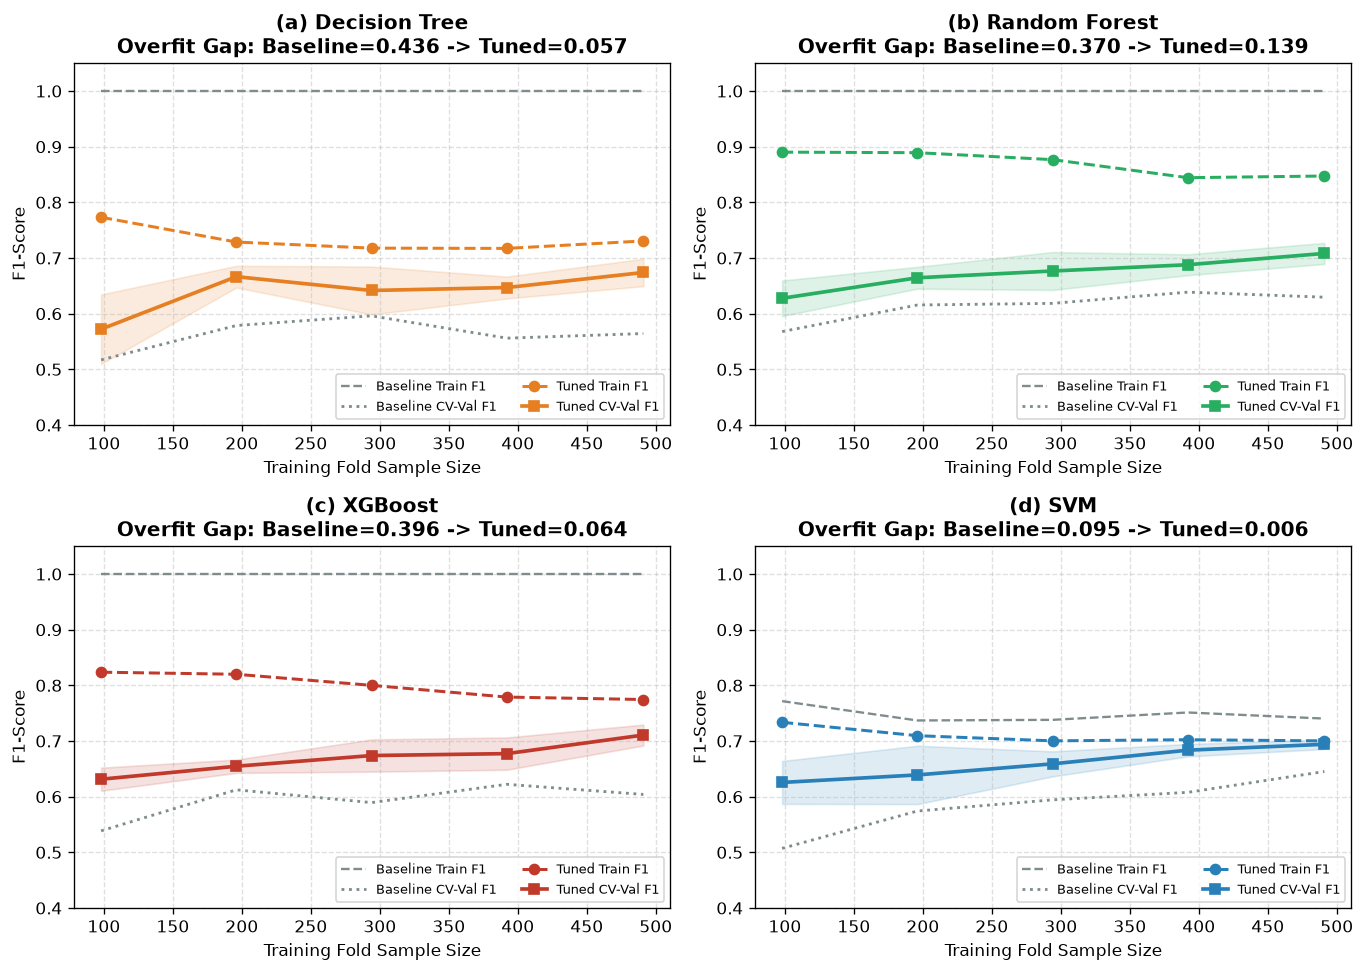

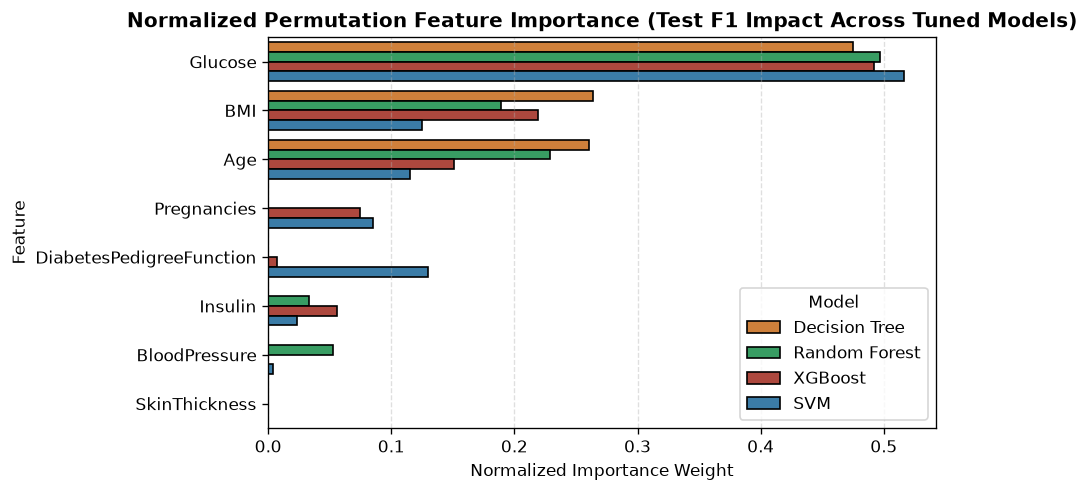

In [8]:
# Cell 8: Bias-Variance Diagnosis via Learning Curves & Permutation Feature Importance
fig, axes = plt.subplots(2, 2, figsize=(11.5, 8.2))
train_fracs = np.linspace(0.2, 1.0, 5)
for idx, m_name in enumerate(model_order):
    ax = axes.flatten()[idx]
    sb, tr_b, val_b = learning_curve(fitted['Exp1_Baseline'][m_name], X_train, y_train, cv=cv, train_sizes=train_fracs, scoring='f1', n_jobs=-1)
    st, tr_t, val_t = learning_curve(fitted['Exp3_Tuned'][m_name], X_train, y_train, cv=cv, train_sizes=train_fracs, scoring='f1', n_jobs=-1)
    ax.plot(sb, np.mean(tr_b, axis=1), '--', color='#7f8c8d', lw=1.4, label='Baseline Train F1')
    ax.plot(sb, np.mean(val_b, axis=1), ':', color='#7f8c8d', lw=1.7, label='Baseline CV-Val F1')
    c = model_colors[m_name]
    tr_tm, val_tm, val_ts = np.mean(tr_t, axis=1), np.mean(val_t, axis=1), np.std(val_t, axis=1)
    ax.plot(st, tr_tm, 'o--', color=c, lw=1.8, label='Tuned Train F1')
    ax.plot(st, val_tm, 's-', color=c, lw=2.2, label='Tuned CV-Val F1')
    ax.fill_between(st, val_tm - val_ts, val_tm + val_ts, color=c, alpha=0.15)
    gap_b = float(np.mean(tr_b[-1]) - np.mean(val_b[-1]))
    gap_t = float(tr_tm[-1] - val_tm[-1])
    ax.set_title(f'({chr(97+idx)}) {m_name}\nOverfit Gap: Baseline={gap_b:.3f} -> Tuned={gap_t:.3f}', fontweight='bold')
    ax.set_xlabel('Training Fold Sample Size')
    ax.set_ylabel('F1-Score')
    ax.set_ylim(0.40, 1.05)
    ax.grid(True, linestyle='--', alpha=0.4)
    ax.legend(loc='lower right', ncol=2, fontsize=7.5)
plt.tight_layout()
plt.show()

# Permutation Feature Importance
perm_rows = []
for m_name in model_order:
    perm = permutation_importance(fitted['Exp3_Tuned'][m_name], X_test, y_test, scoring='f1', n_repeats=30, random_state=RANDOM_STATE, n_jobs=-1)
    imp = np.maximum(perm.importances_mean, 0)
    imp_norm = imp / imp.sum() if imp.sum() > 0 else imp
    for feat, val in zip(FEATURE_COLUMNS, imp_norm):
        perm_rows.append({'Feature': feat, 'Model': m_name, 'Relative_Importance': val})
perm_df = pd.DataFrame(perm_rows)
order_f = perm_df.groupby('Feature')['Relative_Importance'].mean().sort_values(ascending=False).index.tolist()
plt.figure(figsize=(8, 4.2))
sns.barplot(data=perm_df, y='Feature', x='Relative_Importance', hue='Model', order=order_f, palette=model_colors, edgecolor='black')
plt.title('Normalized Permutation Feature Importance (Test F1 Impact Across Tuned Models)', fontweight='bold')
plt.xlabel('Normalized Importance Weight')
plt.grid(axis='x', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

### Conclusion and Final Summary Answering the Research Questions

1. **Resolution of Disguised Missing Data & Prevention of Data Leakage:**
   - Auditing the Pima Indians Diabetes cohort ($N=768$) exposed biologically impossible zero entries in `Insulin` ($48.70\%$), `SkinThickness` ($29.56\%$), `BloodPressure` ($4.56\%$), `BMI` ($1.43\%$), and `Glucose` ($0.65\%$). Encapsulating zero-to-NaN recoding, median imputation, z-score standardization, and SMOTE inside an `imblearn.pipeline.Pipeline` guarantees zero data leakage across cross-validation and hold-out evaluation.
2. **Quantifiable Impact of Imbalance Mitigation and Hyperparameter Optimization:**
   - Unadjusted baseline models suffer from the **accuracy paradox**: while Specificity reaches $0.7900$–$0.8600$, Sensitivity is only $0.4815$–$0.6111$.
   - Combining fold-internal SMOTE with 5-fold stratified hyperparameter optimization (`Exp3_Tuned`) elevates clinical Sensitivity to **$0.7407$–$0.7963$** across all four classifiers while maintaining Specificity between $0.7000$ and $0.7500$.
3. **Bias–Variance Diagnosis from Learning Curves:**
   - Unconstrained baseline tree learners (Decision Tree, Random Forest, and XGBoost) exhibit severe high variance ($F_{1,\text{train}} = 1.0000$, full-fold CV generalization gaps of $0.367$–$0.448$).
   - Structural pruning (`max_depth=4, min_samples_leaf=15` in Decision Tree) and second-order gradient regularization (`max_depth=3, n_estimators=150, learning_rate=0.03, reg_lambda=5.0, min_child_weight=2` in XGBoost) compress the learning-curve gap at $n=491$ to **$0.057$** and **$0.064$**, respectively, while RBF SVM (`C=0.5, gamma=0.03`) converges with a near-zero learning-curve gap of **$0.006$**.
4. **Optimal Model Recommendation:**
   - **Primary Recommendation for Risk Stratification:** **Tuned XGBoost** achieves the highest Test ROC-AUC ($0.8180$) and highest Test PR-AUC ($0.7077$), paired with peak Sensitivity ($0.7963$), strong 5-Fold CV F1 ($0.7078 \pm 0.0217$), and a low generalization gap ($0.0843$, half of Random Forest's $0.1587$).
   - **Primary Recommendation for Rule-Interpretable Point-of-Care Screening:** **Tuned Regularized Decision Tree** achieves the highest fixed-threshold Test F1 ($0.7049$), Sensitivity ($0.7963$), Specificity ($0.7500$), and G-Mean ($0.7728$) with the smallest train-test gap ($0.0165$).